In [1]:
import numpy as np
import geopandas
import xarray as xr
import regionmask

In [2]:
%cd /g/data/w42/dr6273/work/wind_drought

/g/data/w42/dr6273/work/wind_drought


In [3]:
import src.regions

In [4]:
def prepare_regions(gdf, name_col):
    """Prepare a GeoDataFrame and regionmask Regions object."""
    gdf = gdf.to_crs("EPSG:4326").copy()
    gdf["_region_id"] = np.arange(len(gdf))

    regions = regionmask.from_geopandas(
        gdf,
        numbers="_region_id",
        names=name_col,
    )
    return gdf, regions

In [5]:
def align_orog_to_wind(wind_da, orog, lat_name, lon_name):
    land = orog.squeeze(drop=True)

    # Rename orography coordinates to match the wind data.
    rename = {}
    for target, aliases in (
        (lat_name, ("lat", "latitude")),
        (lon_name, ("lon", "longitude")),
    ):
        if target not in land.coords:
            source = next(n for n in aliases if n in land.coords)
            rename[source] = target
    if rename:
        land = land.rename(rename)

    # Convert longitude convention if one grid uses -180..180
    # and the other uses 0..360.
    wind_lon = wind_da[lon_name]
    land_lon = land[lon_name]

    if float(land_lon.min()) < 0 and float(wind_lon.min()) >= 0:
        land = land.assign_coords({lon_name: land_lon % 360})
    elif float(land_lon.max()) > 180 and float(wind_lon.max()) <= 180:
        land = land.assign_coords({lon_name: ((land_lon + 180) % 360) - 180})

    # Interpolate the mask onto the wind grid; nearest preserves its
    # land/ocean classification.
    land = land.sortby(lat_name).sortby(lon_name)
    return land.interp(
        {
            lat_name: wind_da[lat_name],
            lon_name: wind_da[lon_name],
        },
        method="nearest",
    )

In [6]:
def regional_wind_means(wind_da, regions, orog=None):
    """Return an area-weighted time series for each polygon."""
    lat_name = next(n for n in ("lat", "latitude") if n in wind_da.coords)
    lon_name = next(n for n in ("lon", "longitude") if n in wind_da.coords)

    if orog is not None:
        land = align_orog_to_wind(wind_da, orog, lat_name, lon_name)
        wind_da = wind_da.where(land > 0)

    fractions = regions.mask_3D_frac_approx(
        wind_da[lon_name],
        wind_da[lat_name],
        drop=False,
    )

    # Approximate cell-area weights for a regular lon/lat grid.
    weights = fractions * np.cos(np.deg2rad(wind_da[lat_name]))

    spatial_dims = tuple(dict.fromkeys(
        wind_da[lat_name].dims + wind_da[lon_name].dims
    ))

    return wind_da.weighted(weights).mean(spatial_dims)

In [7]:
WIND_PATH = "/g/data/ng72/dr6273/work/projects/wind_drought/data/"

In [8]:
era5_ws = xr.open_zarr(
    WIND_PATH + "ERA5/era5_capacity_factor_100m_1979-2025.zarr/",
    consolidated=False
)["capacity_factor"].isel(time=range(365)).compute()

In [24]:
nem_gdf = geopandas.read_file(
    "data/resource_with_indicative_REZ_boundaries_2026_gis_data.shp",
    # "data/SWIS_transmission_region.shp"
)

In [25]:
scenario = "SC30_wind"

In [26]:
nem_no_qt_gdf = nem_gdf.copy()
nem_no_qt_gdf = nem_no_qt_gdf.rename(columns={"index": "REZ"})
nem_no_qt_gdf = nem_no_qt_gdf.loc[
    nem_no_qt_gdf[scenario].gt(0)
    & ~nem_no_qt_gdf["REZ"].str.startswith(("Q", "T"))
].copy()

In [30]:
nem_no_qt_gdf

,REZ,Name,type,pot_solar,pot_wind,exis_solar,SG30_solar,SG40_solar,SG50_solar,SC30_solar,...,SG30_wind,SG40_wind,SG50_wind,SC30_wind,SC40_wind,SC50_wind,AT30_wind,AT40_wind,AT50_wind,geometry
11,N2,N2 New England,REZ,2985.0,7400.0,1256.0,1256.0,1256.0,2206.0,1456.0,...,702.0,702.0,4102.0,702.0,2452.0,7602.0,702.0,6952.0,8052.0,"POLYGON ((151.97345 -29.41865, 152.02816 -29.4..."
12,N3,N3 Central-West Orana,REZ,4450.0,6850.0,2424.0,4224.0,4224.0,7924.0,4224.0,...,3636.0,3636.0,4586.0,3636.0,4036.0,5136.0,3636.0,4586.0,10886.0,"POLYGON ((149.01083 -31.33683, 149.01105 -31.3..."
13,N4,N4 Broken Hill,REZ,8000.0,5100.0,53.0,53.0,53.0,53.0,353.0,...,198.0,198.0,198.0,198.0,198.0,198.0,298.0,298.0,448.0,"POLYGON ((140.85352 -31.38122, 140.92298 -31.3..."
14,N5,N5 South West NSW,REZ,5677.0,14000.0,1014.0,1214.0,1214.0,1214.0,1214.0,...,3845.0,3845.0,3845.0,3895.0,3895.0,3895.0,3845.0,3845.0,3845.0,"POLYGON ((145.39823 -35.26336, 145.34322 -35.2..."
16,N7,N7 Tumut,REZ,100.0,400.0,0.0,0.0,0.0,0.0,100.0,...,270.0,270.0,270.0,270.0,270.0,270.0,270.0,270.0,370.0,"POLYGON ((148.38778 -34.94197, 148.47117 -34.9..."
17,N8,N8 Cooma-Monaro,REZ,350.0,300.0,0.0,0.0,0.0,0.0,350.0,...,113.0,113.0,113.0,113.0,113.0,313.0,213.0,413.0,613.0,"POLYGON ((149.29244 -35.92343, 149.33262 -35.9..."
18,N9,N9 Hunter-Central Coast,REZ,953.0,1400.0,0.0,1750.0,1750.0,1750.0,2050.0,...,50.0,50.0,1300.0,300.0,1400.0,1500.0,1300.0,3950.0,6150.0,"POLYGON ((151.07816 -32.01056, 151.07817 -32.0..."
21,N12,N12 Illawarra,REZ,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,50.0,50.0,50.0,50.0,350.0,350.0,350.0,"POLYGON ((150.69397 -34.60326, 150.69392 -34.6..."
23,V1,V1 North West VIC,REZ,3000.0,1500.0,30.0,130.0,130.0,130.0,130.0,...,450.0,450.0,450.0,450.0,450.0,450.0,450.0,450.0,1150.0,"POLYGON ((143.92137 -35.76891, 143.92548 -35.7..."
24,V2,V2 Central Highlands VIC,REZ,2500.0,2000.0,125.0,125.0,125.0,125.0,125.0,...,1943.0,1943.0,1943.0,1443.0,1443.0,1893.0,1443.0,1443.0,1943.0,"POLYGON ((143.28868 -37.96547, 143.28585 -37.9..."


In [31]:
nem_gdf = nem_gdf.rename(columns={"index": "REZ"})
nem_gdf = nem_gdf.loc[nem_gdf[scenario].gt(0)].copy()

In [32]:
nem_gdf, nem_regions = prepare_regions(nem_gdf, name_col="REZ")
nem_by_rez = regional_wind_means(era5_ws, nem_regions, orog=None)

In [33]:
nem_equal_mean = nem_by_rez.mean("region", skipna=True)

In [34]:
capacity = xr.DataArray(
    nem_gdf.sort_values("_region_id")[scenario].to_numpy(),
    dims="region",
    coords={"region": nem_by_rez["region"]},
)

In [35]:
nem_capacity_mean = nem_by_rez.weighted(capacity).mean("region")

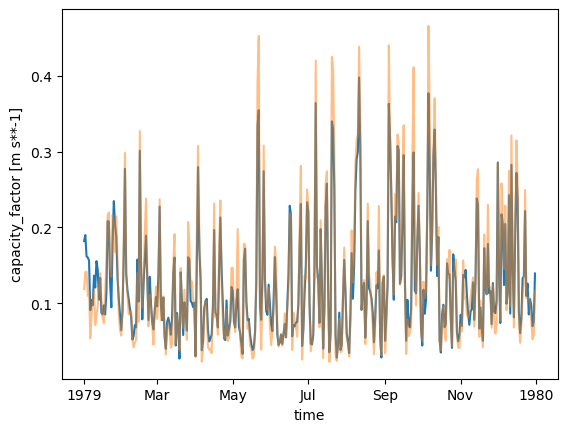

In [36]:
nem_equal_mean.plot()
nem_capacity_mean.plot(alpha=0.5)

In [64]:
str(nem_by_rez.time.dt.year[0].values)

'1979'

In [ ]:
# Start with your GeoDataFrame; its index contains REZ codes such as "V8".
swis_gdf = geopandas.read_file(
    # "data/resource_with_indicative_REZ_boundaries_2026_gis_data.shp",
    "data/SWIS_transmission_region.shp"
)

In [54]:
# orog = xr.open_mfdataset(
#     "/g/data/rt52/era5/single-levels/monthly-averaged/lsm/2025/lsm_era5_moda_sfc_20250101-20250131.nc"
# )["lsm"]

In [57]:
orog = xr.open_dataset(
    "/g/data/ob53/BARRA2/output/reanalysis/AUS-11/BOM/ERA5/historical/hres/BARRA-R2/v1/fx/orog/latest/orog_AUS-11_ERA5_historical_hres_BOM_BARRA-R2_v1.nc"
)["orog"]#.sel(lat=barraR2_grid_mask.lat, lon=barraR2_grid_mask.lon).drop_vars("crs")

In [59]:
barra_ws = xr.open_zarr(
    WIND_PATH + "BARRA-R2/barra-r2_capacity_factor_100m_1979-2025.zarr/",
    consolidated=False
)["capacity_factor"].isel(time=range(365)).compute()

In [60]:
swis_gdf, swis_regions = prepare_regions(swis_gdf, name_col="region")
# nwis_gdf, nwis_regions = prepare_regions(nwis_gdf, name_col="region")

swis_mean = regional_wind_means(barra_ws, swis_regions, orog=orog).isel(
    region=0, drop=True
)
# nwis_mean = regional_wind_means(wind_da, nwis_regions, orog=orog).isel(
#     region=0, drop=True
# )

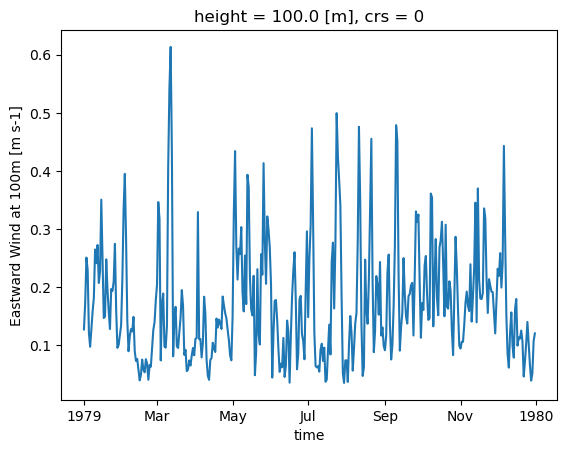

In [61]:
swis_mean.plot()

In [17]:
lsm_era5 = xr.open_mfdataset(
    "/g/data/rt52/era5/single-levels/monthly-averaged/lsm/2025/lsm_era5_moda_sfc_20250101-20250131.nc"
)["lsm"]

In [19]:
orog_barraR2 = xr.open_dataset(
    "/g/data/ob53/BARRA2/output/reanalysis/AUS-11/BOM/ERA5/historical/hres/BARRA-R2/v1/fx/orog/latest/orog_AUS-11_ERA5_historical_hres_BOM_BARRA-R2_v1.nc"
)["orog"]#.sel(lat=barraR2_grid_mask.lat, lon=barraR2_grid_mask.lon).drop_vars("crs")

In [20]:
orog = lsm_era5

In [22]:
print(orog)

<xarray.DataArray 'lsm' (time: 1, latitude: 721, longitude: 1440)> Size: 8MB
dask.array<open_dataset-lsm, shape=(1, 721, 1440), dtype=float64, chunksize=(1, 721, 1440), chunktype=numpy.ndarray>
Coordinates:
  * time       (time) datetime64[ns] 8B 2025-01-01
  * latitude   (latitude) float32 3kB 90.0 89.75 89.5 ... -89.5 -89.75 -90.0
  * longitude  (longitude) float32 6kB -180.0 -179.8 -179.5 ... 179.5 179.8
Attributes:
    units:          (0 - 1)
    long_name:      Land-sea mask
    standard_name:  land_binary_mask


In [7]:
scenario = "SC30_wind"

In [ ]:
gdf["REZ"] = gdf.index
# Keep only REZs with positive wind capacity.
gdf = gdf.loc[gdf[scenario].gt(0)].copy()

gdf = gdf.to_crs("EPSG:4326")  # if the data coordinates are lon/lat
gdf["_region_id"] = np.arange(len(gdf))

In [ ]:
regions = regionmask.from_geopandas(
    gdf,
    numbers="_region_id",
    names="index",
)

In [8]:
# def rez_wind_averages(wind_da, gdf, regions, wind_scenario="SC30_wind"):
#     # For a regular, equally spaced lon/lat grid.
#     fractions = regions.mask_3D_frac_approx(wind_da, drop=False).drop_vars('abbrevs')

#     # Approximate grid-cell area weights for a regular lon/lat grid.
#     cell_area_weights = np.cos(np.deg2rad(wind_da["lat"]))
#     spatial_weights = fractions * cell_area_weights

#     # One area-weighted time series per REZ.
#     by_rez = wind_da.weighted(spatial_weights).mean(("lat", "lon"))

#     # Match each mask region ID to its wind capacity.
#     meta = gdf.set_index("_region_id").reindex(by_rez["region"].values)
#     capacity = xr.DataArray(
#         meta[wind_scenario].fillna(0).to_numpy(),
#         dims="region",
#         coords={"region": by_rez["region"]},
#     )

#     # Same weight for every REZ.
#     equal_rez_mean = by_rez.mean("region", skipna=True)

#     # Weight REZ means by wind capacity.
#     capacity_weighted_mean = by_rez.weighted(capacity).mean("region")

#     return equal_rez_mean, capacity_weighted_mean, by_rez

In [12]:
equal_rez, cap_weighted, by_rez = src.regions.rez_wind_averages(era5_ws, gdf, regions)

In [13]:
by_rez

<xarray.DataArray 'capacity_factor' (time: 365, region: 30)> Size: 88kB
array([[0.66165708, 0.37490514, 0.30117296, ..., 0.29811402, 0.24526362,
        0.24246851],
       [0.59943396, 0.42288741, 0.32985423, ..., 0.13201365, 0.2013233 ,
        0.17627893],
       [0.33458536, 0.44713559, 0.34936854, ..., 0.0683905 , 0.19197058,
        0.04548739],
       ...,
       [0.01420168, 0.18363057, 0.12316806, ..., 0.01748889, 0.05217787,
        0.01844086],
       [0.06485076, 0.11811304, 0.11595083, ..., 0.0625058 , 0.07706455,
        0.08657389],
       [0.04318025, 0.05715702, 0.04804161, ..., 0.11009576, 0.19756469,
        0.02571336]], shape=(365, 30))
Coordinates:
  * time     (time) datetime64[ns] 3kB 1979-01-01 1979-01-02 ... 1979-12-31
  * region   (region) int64 240B 0 1 2 3 4 5 6 7 8 ... 22 23 24 25 26 27 28 29
    names    (region) <U3 360B 'Q1' 'Q2' 'Q3' 'Q4' 'Q5' ... 'S7' 'T1' 'T2' 'T3'
Attributes:
    units:    m s**-1

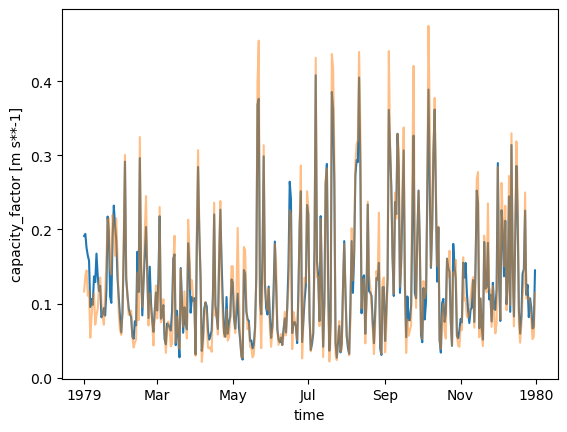

In [95]:
equal_rez.plot()
cap_weighted.plot(alpha=0.5)